# Compare logged models

Run all cells to reload `training/logs`. This notebook shows training curves,
step-weighted model comparisons, and evaluation step counts. It reads logs only;
model zip files and a running simulator are not required.

A **finished training run** ends at its step or wall-clock limit and records a saved
model. A **complete evaluation** contains every requested run, with each run marked
`completed`. Failed screening results remain visible: **completed does not mean
passed**. The evaluation step chart excludes interrupted training and incomplete
reports. Evaluation steps include resets after lane failures; they do not count
laps. Physical-bot trial reports are excluded.


In [31]:
from pathlib import Path
import json
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter, MaxNLocator
from IPython.display import display

PROJECT_ROOT = next((p for p in (Path.cwd(), *Path.cwd().parents)
                     if (p / "training").is_dir() and (p / "scripts").is_dir()), None)
if PROJECT_ROOT is None:
    raise RuntimeError("Open this notebook from the project or its scripts directory")
LOGS_DIR = PROJECT_ROOT / "training" / "logs"  # Change to inspect another log archive.
SMOOTHING_WINDOW = 1  # Number of logged batches; 1 shows the recorded values.
EXPORT_DIR = None     # Optional Path for exported PNG plots.
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": .2})


In [32]:
def model_name(value):
    return str(value).replace("\\", "/").rsplit("/", 1)[-1].removesuffix(".zip")


def read_training_curve(folder):
    """Progress steps are cumulative; batch_rewards steps are batch sizes."""
    for filename in ("progress.csv", "batch_rewards.csv"):
        path = folder / filename
        if not path.exists():
            continue
        try:
            frame = pd.read_csv(path, on_bad_lines="skip")
        except (pd.errors.EmptyDataError, pd.errors.ParserError, OSError) as error:
            warnings.warn(f"Cannot read {path}: {error}")
            continue
        required = ("steps", "both_lines_fraction")
        if not all(column in frame for column in required):
            continue
        if filename == "progress.csv" and "reward_per_step" not in frame:
            continue
        if filename == "batch_rewards.csv" and "reward_total" not in frame:
            continue
        numeric = (*required, "reward_per_step" if filename == "progress.csv" else "reward_total")
        frame = frame.copy()
        for column in numeric:
            frame[column] = pd.to_numeric(frame[column], errors="coerce")
        # A live writer can leave a partial final row. Ignore incomplete rows.
        frame = frame.dropna(subset=list(numeric))
        frame = frame[np.isfinite(frame[list(numeric)]).all(axis=1) & (frame.steps > 0)]
        if frame.empty:
            continue
        if filename == "progress.csv":
            frame = frame.sort_values("steps").drop_duplicates("steps", keep="last")
            frame["weight"] = frame.steps.diff().fillna(frame.steps.iloc[0])
        else:
            frame["weight"] = frame.steps
            frame["reward_per_step"] = frame.reward_total / frame.weight
            frame["steps"] = frame.weight.cumsum()
        frame = frame[(frame.weight > 0) & frame.both_lines_fraction.between(0, 1)]
        if not frame.empty:
            return frame[["steps", "weight", "reward_per_step", "both_lines_fraction"]].reset_index(drop=True)
    return pd.DataFrame(columns=["steps", "weight", "reward_per_step", "both_lines_fraction"])


def evaluation_complete(report):
    runs = report.get("runs", [])
    requested = report.get("requested_runs")
    return (isinstance(requested, int) and requested > 0 and len(runs) == requested
            and not report.get("error")
            and all(run.get("completed") is True and run.get("steps", 0) > 0 for run in runs))


def load_logged_models(logs_dir):
    entries, curves = {}, {}
    diagnostics = []
    folders = {p.parent for filename in ("progress.csv", "batch_rewards.csv")
               for p in logs_dir.rglob(filename)} if logs_dir.exists() else set()
    reports = []
    for path in sorted(logs_dir.rglob("*.json")) if logs_dir.exists() else []:
        try:
            report = json.loads(path.read_text())
        except (OSError, ValueError) as error:
            diagnostics.append(f"Skipped unreadable report {path.name}: {error}")
            continue
        if not isinstance(report, dict) or "hostname" in report:
            continue
        if "evaluation" in report and "settings" in report:
            folders.add(path.parent)
            name = model_name(report.get("model") or path.parent.name)
            finished = (bool(report.get("model")) and report.get("steps", 0) > 0
                        and not report.get("error")
                        and report.get("stop_reason") in ("step limit", "wall-clock limit"))
            entries[name] = dict(model=name, training_finished=finished, training_steps=report.get("steps", 0),
                                 status=report.get("stop_reason", "unknown"), training_report=str(path))
            report["_model_name"] = name
            reports.append((path, report, True))
        elif "model" in report and "runs" in report:
            name = model_name(report["model"])
            entries.setdefault(name, dict(model=name, training_finished=None, training_steps=np.nan,
                                         status="evaluation only", training_report=""))
            report["_model_name"] = name
            reports.append((path, report, False))
    for folder in sorted(folders):
        training = next((report for path, report, is_training in reports
                         if is_training and path.parent == folder), None)
        name = training["_model_name"] if training else folder.name
        curve = read_training_curve(folder)
        curves[name] = curve
        entry = entries.setdefault(name, dict(model=name, training_finished=False,
                                              training_steps=0, status="in progress", training_report=""))
        entry["logged_training_steps"] = int(curve.weight.sum()) if not curve.empty else 0
        if not curve.empty:
            entry["training_reward_per_step"] = np.average(curve.reward_per_step, weights=curve.weight)
            entry["training_both_lines_fraction"] = np.average(curve.both_lines_fraction, weights=curve.weight)
            if entry["status"] == "in progress":
                entry["training_steps"] = int(curve.steps.iloc[-1])
    evaluations = {}
    for path, outer, is_training in reports:
        report = outer.get("evaluation") if is_training else outer
        if not isinstance(report, dict) or not isinstance(report.get("runs"), list) or not report["runs"]:
            continue
        name = outer["_model_name"]
        candidate = dict(report)
        # An exception in the outer file must not look like a completed evaluation.
        if outer.get("error"):
            candidate["error"] = outer["error"]
        candidate["source"] = str(path)
        candidate["rank"] = (evaluation_complete(candidate), path.stat().st_mtime_ns)
        if name not in evaluations or candidate["rank"] > evaluations[name]["rank"]:
            evaluations[name] = candidate
    for name, entry in entries.items():
        report = evaluations.get(name)
        entry["evaluation_complete"] = bool(report and evaluation_complete(report))
        entry["evaluation_source"] = report.get("source", "") if report else ""
        entry["evaluation_passed"] = report.get("passed") if report else None
        if report:
            runs = pd.DataFrame(report["runs"])
            for column in ("steps", "reward_total", "reward_per_step", "both_lines_fraction", "failures"):
                if column not in runs:
                    runs[column] = np.nan
                runs[column] = pd.to_numeric(runs[column], errors="coerce")
            valid = runs[(runs.steps > 0) & np.isfinite(runs.steps)]
            entry["evaluation_steps"] = int(valid.steps.sum())
            entry["evaluation_failures"] = int(valid.failures.fillna(0).sum())
            for metric in ("reward_per_step", "both_lines_fraction"):
                usable = valid[np.isfinite(valid[metric])]
                if not usable.empty:
                    entry[f"evaluation_{metric}"] = np.average(usable[metric], weights=usable.steps)
    columns = ["model", "status", "training_finished", "training_steps", "logged_training_steps",
               "training_reward_per_step", "training_both_lines_fraction", "evaluation_reward_per_step",
               "evaluation_both_lines_fraction", "evaluation_steps", "evaluation_failures",
               "evaluation_complete", "evaluation_passed", "training_report", "evaluation_source"]
    table = pd.DataFrame(entries.values()).reindex(columns=columns).sort_values("model").reset_index(drop=True)
    table.insert(0, "label", [f"M{i+1:02}" for i in range(len(table))])
    return table, curves, evaluations, diagnostics


def complete_evaluations(table, evaluations):
    # Standalone evaluate.py reports can be complete without a local training log.
    return {row.model: evaluations[row.model] for row in table.itertuples()
            if row.evaluation_complete and row.training_finished is not False
            and row.model in evaluations}


def finish_plot(figure, name):
    figure.tight_layout()
    if EXPORT_DIR is not None:
        Path(EXPORT_DIR).mkdir(parents=True, exist_ok=True)
        figure.savefig(Path(EXPORT_DIR) / f"{name}.png", dpi=180, bbox_inches="tight")
    plt.show()


In [33]:
models, curves, evaluations, diagnostics = load_logged_models(Path(LOGS_DIR))
print(f"Loaded {len(models)} logged models from {LOGS_DIR}")
for message in diagnostics:
    print(message)
if models.empty:
    print("No training or evaluation logs found yet. Run training or save evaluate.py --output under training/logs.")
else:
    display(models.drop(columns=["training_report", "evaluation_source"]))
    display(models[["label", "model", "training_report", "evaluation_source"]])


Loaded 11 logged models from /home/svandenberk/Downloads/Duckiebot_Lab_Starter_Kit/MOL_VaSe_VaSe_Duckie/training/logs


,label,model,status,training_finished,training_steps,logged_training_steps,training_reward_per_step,training_both_lines_fraction,evaluation_reward_per_step,evaluation_both_lines_fraction,evaluation_steps,evaluation_failures,evaluation_complete,evaluation_passed
0,M01,dqn_simple_20261015_132059_988128_lr0.0003_spe...,wall-clock limit,True,29534,29534,0.634508,0.918602,0.779186,0.987041,5942.0,1.0,True,False
1,M02,dqn_simple_20261015_132709_160772_lr0.0003_spe...,interrupted,False,936,936,0.288215,0.746795,NaN,NaN,NaN,NaN,False,None
2,M03,dqn_simple_20261015_132827_718975_lr1e-05_spee...,interrupted,False,9886,9886,0.164237,0.695327,NaN,NaN,NaN,NaN,False,None
3,M04,dqn_simple_20261015_133848_334137_lr1e-05_spee...,wall-clock limit,True,28631,28631,-0.151051,0.488177,-0.130701,0.488214,5727.0,70.0,True,False
4,M05,dqn_simple_20261015_134413_250690_lr1e-05_spee...,unknown,False,0,0,NaN,NaN,NaN,NaN,NaN,NaN,False,None
5,M06,dqn_simple_20261015_134526_147264_lr1e-05_spee...,wall-clock limit,True,28305,28305,-0.345470,0.388483,-0.231167,0.459839,5702.0,75.0,True,False
6,M07,dqn_simple_20261015_135250_477394_lr1e-05_spee...,wall-clock limit,True,29620,29620,0.605948,0.928325,0.667123,0.945828,5944.0,0.0,True,True
7,M08,dqn_simple_20261015_140208_109026_lr1e-05_spee...,wall-clock limit,True,29624,29624,0.685045,0.972624,0.729792,1.000000,5943.0,0.0,True,True
8,M09,dqn_simple_20261015_142218_017273_lr1e-05_spee...,wall-clock limit,True,29671,29671,0.628282,0.937211,0.592551,0.890372,5920.0,7.0,True,False
9,M10,dqn_simple_20261015_142420_850916_lr1e-06_spee...,wall-clock limit,True,29684,29684,0.667193,0.978103,0.676647,0.980802,5938.0,0.0,True,True


,label,model,training_report,evaluation_source
0,M01,dqn_simple_20261015_132059_988128_lr0.0003_spe...,/home/svandenberk/Downloads/Duckiebot_Lab_Star...,/home/svandenberk/Downloads/Duckiebot_Lab_Star...
1,M02,dqn_simple_20261015_132709_160772_lr0.0003_spe...,/home/svandenberk/Downloads/Duckiebot_Lab_Star...,
2,M03,dqn_simple_20261015_132827_718975_lr1e-05_spee...,/home/svandenberk/Downloads/Duckiebot_Lab_Star...,
3,M04,dqn_simple_20261015_133848_334137_lr1e-05_spee...,/home/svandenberk/Downloads/Duckiebot_Lab_Star...,/home/svandenberk/Downloads/Duckiebot_Lab_Star...
4,M05,dqn_simple_20261015_134413_250690_lr1e-05_spee...,/home/svandenberk/Downloads/Duckiebot_Lab_Star...,
5,M06,dqn_simple_20261015_134526_147264_lr1e-05_spee...,/home/svandenberk/Downloads/Duckiebot_Lab_Star...,/home/svandenberk/Downloads/Duckiebot_Lab_Star...
6,M07,dqn_simple_20261015_135250_477394_lr1e-05_spee...,/home/svandenberk/Downloads/Duckiebot_Lab_Star...,/home/svandenberk/Downloads/Duckiebot_Lab_Star...
7,M08,dqn_simple_20261015_140208_109026_lr1e-05_spee...,/home/svandenberk/Downloads/Duckiebot_Lab_Star...,/home/svandenberk/Downloads/Duckiebot_Lab_Star...
8,M09,dqn_simple_20261015_142218_017273_lr1e-05_spee...,/home/svandenberk/Downloads/Duckiebot_Lab_Star...,/home/svandenberk/Downloads/Duckiebot_Lab_Star...
9,M10,dqn_simple_20261015_142420_850916_lr1e-06_spee...,/home/svandenberk/Downloads/Duckiebot_Lab_Star...,/home/svandenberk/Downloads/Duckiebot_Lab_Star...


## Training curves

One line per logged model. The x-axis is the steps added in that training run,
including warm starts. Smoothing, when enabled, is weighted by the number of steps
in each logged batch. An unfinished model is labelled in progress.


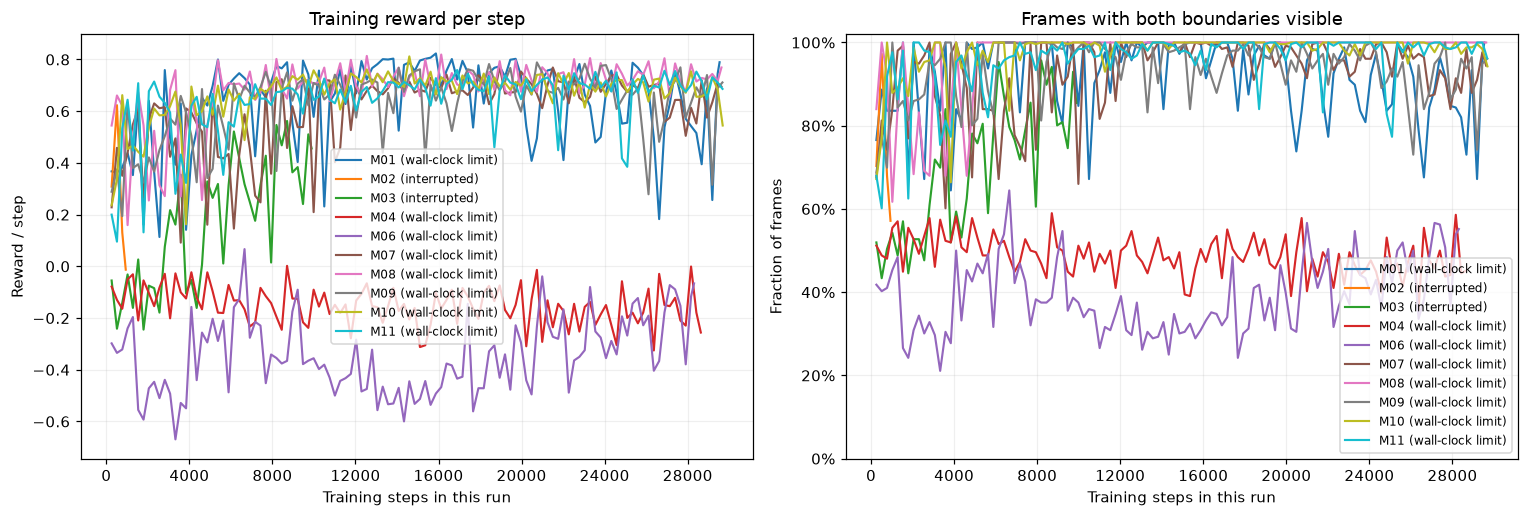

In [34]:
if not models.empty and any(not curve.empty for curve in curves.values()):
    fig, axes = plt.subplots(1, 2, figsize=(14, 4.8))
    window = max(1, int(SMOOTHING_WINDOW))
    for row in models.itertuples():
        curve = curves.get(row.model)
        if curve is None or curve.empty:
            continue
        label = f"{row.label} ({row.status})"
        weights = curve.weight.rolling(window, min_periods=1).sum()
        for axis, metric in zip(axes, ("reward_per_step", "both_lines_fraction")):
            values = (curve[metric] * curve.weight).rolling(window, min_periods=1).sum() / weights
            axis.plot(curve.steps, values, label=label, linewidth=1.4)
    axes[0].set(title="Training reward per step", ylabel="Reward / step")
    axes[1].set(title="Frames with both boundaries visible", ylabel="Fraction of frames", ylim=(0, 1.02))
    axes[1].yaxis.set_major_formatter(PercentFormatter(1))
    for axis in axes:
        axis.set_xlabel("Training steps in this run")
        axis.xaxis.set_major_locator(MaxNLocator(integer=True))
        axis.legend(fontsize=8)
    finish_plot(fig, "model_training_curves")
else:
    print("No training curves available.")


## Compare every logged model

Bars show step-weighted averages for training and evaluation separately. Missing
metrics leave a gap. The model labels refer to the tables above. Evaluation bars
may describe a partial evaluation; the completeness flag is shown in the table.


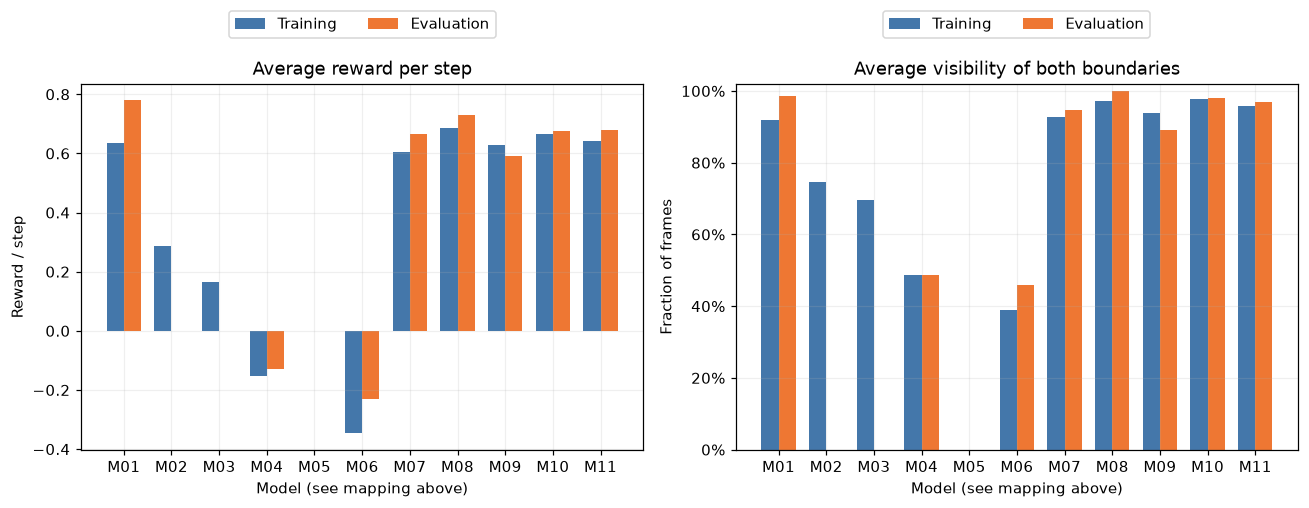

In [35]:
if not models.empty:
    fig, axes = plt.subplots(1, 2, figsize=(max(12, len(models) * .8), 4.8))
    x = np.arange(len(models))
    for axis, metric, title in zip(axes,
            ("reward_per_step", "both_lines_fraction"),
            ("Average reward per step", "Average visibility of both boundaries")):
        for delta, phase, color in ((-.18, "training", "#4477AA"), (.18, "evaluation", "#EE7733")):
            values = pd.to_numeric(models[f"{phase}_{metric}"], errors="coerce")
            axis.bar(x + delta, values, width=.36, color=color, label=phase.capitalize())
        axis.set(title=title, xticks=x, xticklabels=models.label)
        axis.legend(loc="upper center", bbox_to_anchor=(.5, 1.22), ncol=2)
        axis.set_xlabel("Model (see mapping above)")
    axes[0].set_ylabel("Reward / step")
    axes[1].set(ylabel="Fraction of frames", ylim=(0, 1.02))
    axes[1].yaxis.set_major_formatter(PercentFormatter(1))
    finish_plot(fig, "model_metric_comparison")
else:
    print("No models to compare.")


## Evaluation step counts for completely finished models

Each stacked segment is one completed `evaluate.py` run, including the evaluations
called by `train.py`. The number above each bar is the total evaluation steps.
Models that completed their time budget but failed screening are explicitly marked.
Reports missing runs, shortened by a deadline, interrupted, or containing errors
are excluded. If multiple reports exist for the same model, use the newest complete
report; an incomplete rerun does not erase a previous complete result.


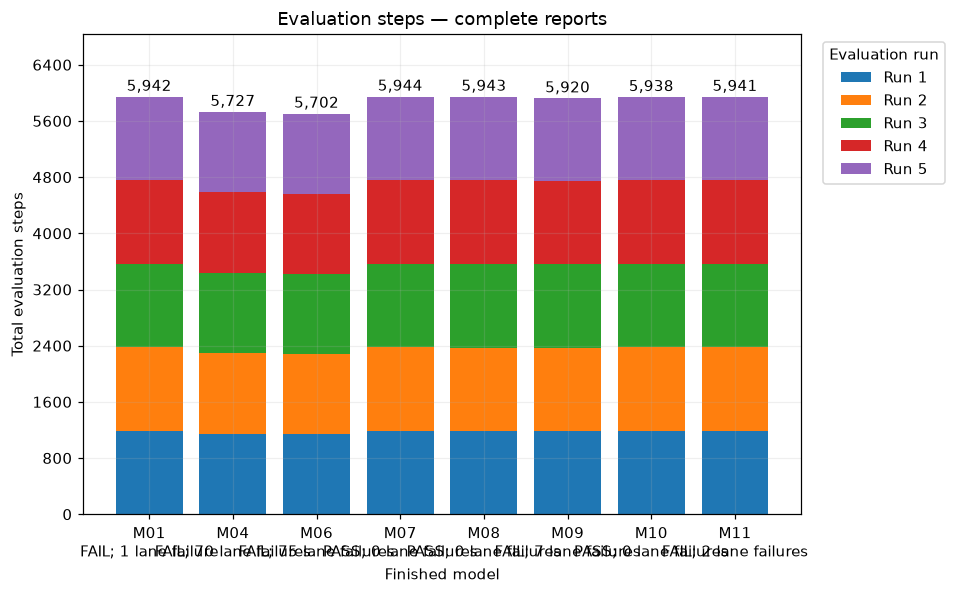

,label,model,training_steps,evaluation_steps,evaluation_failures,evaluation_passed
0,M01,dqn_simple_20261015_132059_988128_lr0.0003_spe...,29534,5942.0,1.0,False
1,M04,dqn_simple_20261015_133848_334137_lr1e-05_spee...,28631,5727.0,70.0,False
2,M06,dqn_simple_20261015_134526_147264_lr1e-05_spee...,28305,5702.0,75.0,False
3,M07,dqn_simple_20261015_135250_477394_lr1e-05_spee...,29620,5944.0,0.0,True
4,M08,dqn_simple_20261015_140208_109026_lr1e-05_spee...,29624,5943.0,0.0,True
5,M09,dqn_simple_20261015_142218_017273_lr1e-05_spee...,29671,5920.0,7.0,False
6,M10,dqn_simple_20261015_142420_850916_lr1e-06_spee...,29684,5938.0,0.0,True
7,M11,dqn_simple_20261015_142523_119271_lr1e-06_spee...,29675,5941.0,2.0,False


In [36]:
finished = complete_evaluations(models, evaluations)
if finished:
    rows = models[models.model.isin(finished)].reset_index(drop=True)
    fig, axis = plt.subplots(figsize=(max(8, len(rows) * 1.1), 5.5))
    x = np.arange(len(rows))
    bottoms = np.zeros(len(rows))
    for index in range(max(len(report["runs"]) for report in finished.values())):
        counts = [finished[name]["runs"][index]["steps"]
                  if index < len(finished[name]["runs"]) else 0 for name in rows.model]
        axis.bar(x, counts, bottom=bottoms, label=f"Run {index+1}")
        bottoms += np.asarray(counts)
    labels = [f"{row.label}\n{'PASS' if row.evaluation_passed else 'FAIL'}; {int(row.evaluation_failures)} lane {'failure' if row.evaluation_failures == 1 else 'failures'}"
              for row in rows.itertuples()]
    axis.set(title="Evaluation steps — complete reports", ylabel="Total evaluation steps",
             xlabel="Finished model", xticks=x, xticklabels=labels)
    for position, count in zip(x, bottoms):
        axis.annotate(f"{int(count):,}", (position, count), xytext=(0, 4),
                      textcoords="offset points", ha="center", fontsize=10)
    axis.set_ylim(0, max(bottoms) * 1.15)
    axis.yaxis.set_major_locator(MaxNLocator(integer=True))
    axis.legend(title="Evaluation run", bbox_to_anchor=(1.02, 1), loc="upper left")
    finish_plot(fig, "completed_model_evaluation_steps")
    display(rows[["label", "model", "training_steps", "evaluation_steps",
                  "evaluation_failures", "evaluation_passed"]])
else:
    print("No fully finished models with complete evaluation reports yet.")
